# Tugas 4 Bagian B dan C: Peta Aduan

Memakai hasil audit `00_audit_geospasial.ipynb`. Teks aduan hanya diproses, tidak ditampilkan.

In [1]:
import json
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="A NumPy version")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch, Polygon
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer

DATA = Path("../../week9/datasets")
FIG = Path("figure")
FIG.mkdir(exist_ok=True)
BIRU, ABU, TEKS, TEKS2 = "#2a78d6", "#c4c2bb", "#0b0b0b", "#52514e"
RAMP = ["#dbe9f9", "#8fbcef", "#2a78d6", "#0d366b"]
plt.rcParams.update({"figure.facecolor": "white", "savefig.dpi": 200, "font.size": 10,
                     "axes.edgecolor": TEKS2, "xtick.color": TEKS2, "ytick.color": TEKS2})

g = pd.read_csv("../datasets/aduan_geo.csv", dtype={"id_aduan": str}, parse_dates=["tanggal_baku"])
b = pd.read_csv(DATA / "aduan_bersih.csv", usecols=["id_aduan", "token"], dtype={"id_aduan": str})
df = b.merge(g, on="id_aduan", validate="one_to_one")
df["token"] = df.token.fillna("")
w = pd.read_csv(DATA / "wilayah_kota_sukaraya.csv").set_index("kelurahan")
geo = json.load(open(DATA / "wilayah_kota_sukaraya.geojson"))
print(len(df), "aduan |", df.untuk_titik.sum(), "untuk peta titik")

4785 aduan | 4640 untuk peta titik


## 1. Pengklasifikasi kategori dari Tugas 3

In [2]:
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.5, token_pattern=r"\S+")
X = vec.fit_transform(df.token)
istilah = np.array(vec.get_feature_names_out())
nmf = NMF(16, init="nndsvd", random_state=0, max_iter=500)
W = nmf.fit_transform(X)
puncak = [istilah[h.argsort()[::-1][0]] for h in nmf.components_]
T_AIR = [k for k, p in enumerate(puncak) if p == "air"]
T_BADAN = [k for k, p in enumerate(puncak) if p == "badan jalan"]

KERUH = {"keruh", "kekuningan", "lumpur", "coklat", "kaporit", "mengendap"}
ATURAN = {
    "air": [("air keruh", KERUH),
            ("genangan", {"menggenang", "banjir", "saluran", "gorong", "drainase", "lutut", "meluber"}),
            ("air tidak mengalir", {"mengalir", "pdam", "keran"})],
    "badan": [("parkir liar", {"parkir", "liar"}), ("sampah", {"sampah", "berserakan"})],
    "T13": [("sampah", {"limbah"}), ("genangan", {"jebol"}), ("respon lambat", {"menegur", "digubris"})],
    "sisa": [("pohon", {"lapuk", "miring", "tumbang"}), ("kabel menjuntai", {"kabel", "menjuntai"}),
             ("bising bengkel", {"bising", "bengkel"}), ("angkutan", {"angkutan", "berhenti", "sembarangan"})],
}
GABUNG = {0: "jalan", 3: "jalan", 7: "jalan", 10: "jalan", 1: "lampu", 9: "lampu", 11: "lampu",
          2: "sampah", 6: "sampah", 8: "sampah", 12: "sampah", 15: "genangan", 13: "T13", 14: "pkl"}

def pecah(teks, aturan):
    kata = set(teks.split())
    return next((label for label, penanda in aturan if kata & penanda), "Tidak jelas")

kategori = []
for teks, k, bobot in zip(df.token, W.argmax(1), W.max(1)):
    if bobot < .02:
        kategori.append("Tidak jelas")
    elif k in T_AIR:
        kategori.append(pecah(teks, ATURAN["air"]))
    elif k in T_BADAN:
        kategori.append(pecah(teks, ATURAN["badan"]))
    else:
        kategori.append(GABUNG.get(k, f"T{k}"))
df["kategori"] = kategori
for kunci, syarat in (("T13", "T13"), ("sisa", "Tidak jelas")):
    m = df.kategori == syarat
    df.loc[m, "kategori"] = df.loc[m, "token"].map(lambda t: pecah(t, ATURAN[kunci]))
df.loc[df.token.str.split().map(lambda k: bool(set(k) & KERUH)), "kategori"] = "air keruh"
df["kategori_t3"] = df.kategori

# Perbaikan: aduan berpenanda kerusakan jalan masuk kategori jalan
PENANDA_JALAN = {"lubang", "berlubang", "terjatuh", "berbatu"}
berpenanda = df.token.str.split().map(lambda k: bool(set(k) & PENANDA_JALAN))
pindah = berpenanda & ~df.kategori.isin(["jalan", "air keruh"])
df.loc[pindah, "kategori"] = "jalan"
print("dipindah ke jalan:", pindah.sum(), df.kategori_t3[pindah].value_counts().to_dict())
print("berpenanda keruh dan jalan, tetap air keruh:", (berpenanda & (df.kategori == "air keruh")).sum())
df.kategori.value_counts()

dipindah ke jalan: 27 {'respon lambat': 26, 'pkl': 1}
berpenanda keruh dan jalan, tetap air keruh: 0


kategori
jalan                 1099
lampu                 1089
sampah                 996
genangan               535
parkir liar            223
respon lambat          150
air keruh              146
pohon                  144
pkl                    107
air tidak mengalir      90
angkutan                83
kabel menjuntai         64
bising bengkel          56
Tidak jelas              3
Name: count, dtype: int64

## 2. Aduan per km² dengan 4 kelas interval sama

In [3]:
t = pd.DataFrame({"aduan": df.kel_final.value_counts(), "penduduk": w.jumlah_penduduk, "luas": w.luas_km2})
t["per_km2"] = t.aduan / t.luas
t["per_1000"] = t.aduan / t.penduduk * 1000
AMBANG = np.linspace(t.per_km2.min(), t.per_km2.max(), 5)
t["kelas"] = np.digitize(t.per_km2, AMBANG[1:-1])
print("ambang:", AMBANG.round(1).tolist(), "| lebar kelas:", round(AMBANG[1] - AMBANG[0], 1))
print("isi kelas:", t.kelas.value_counts().sort_index().to_dict())
t.sort_values("per_km2", ascending=False).round(2)

ambang: [34.6, 72.3, 110.0, 147.6, 185.3] | lebar kelas: 37.7
isi kelas: {0: 4, 1: 5, 2: 2, 3: 1}


,aduan,penduduk,luas,per_km2,per_1000,kelas
Babakan Sari,819,62400,4.42,185.29,13.12,3
Kebon Gedang,596,18300,4.42,134.84,32.57,2
Mekarjaya,534,52100,4.42,120.81,10.25,2
Rancabolang,463,44900,4.42,104.75,10.31,1
Sekejati,450,38600,4.42,101.81,11.66,1
Cibuntu Kaler,415,33800,4.42,93.89,12.28,1
Cikawao,330,27500,4.42,74.66,12.00,1
Antapani Wetan,330,30200,4.42,74.66,10.93,1
Cisaranten,262,21700,4.42,59.28,12.07,0
Margahayu Kidul,238,24800,4.42,53.85,9.60,0


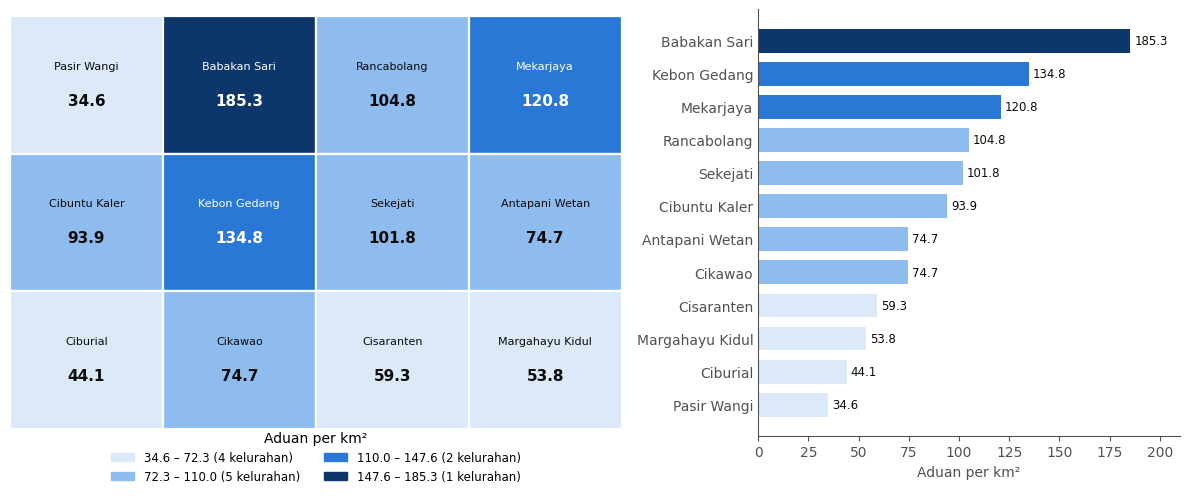

In [4]:
def gambar_batas(ax, warna=None):
    for f in geo["features"]:
        nama = f["properties"].get("kelurahan") or f["properties"].get("nama")
        isi = warna[nama] if warna else "none"
        ax.add_patch(Polygon(f["geometry"]["coordinates"][0], closed=True, facecolor=isi,
                             edgecolor="white" if warna else TEKS2, linewidth=1.6 if warna else .7, zorder=3 if not warna else 1))
    ax.set_xlim(107.56, 107.64); ax.set_ylim(-6.934, -6.88); ax.set_aspect("equal"); ax.axis("off")

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1.45, 1]})
gambar_batas(ax, {n: RAMP[k] for n, k in t.kelas.items()})
for n, r in t.iterrows():
    c = "white" if r.kelas >= 2 else TEKS
    ax.text(w.lon_pusat[n], w.lat_pusat[n] + .0025, n, ha="center", va="center", fontsize=8, color=c)
    ax.text(w.lon_pusat[n], w.lat_pusat[n] - .002, f"{r.per_km2:.1f}", ha="center", va="center", fontsize=11, fontweight="bold", color=c)
isi = t.kelas.value_counts().sort_index()
ax.legend(handles=[Patch(color=RAMP[i], label=f"{AMBANG[i]:.1f} – {AMBANG[i + 1]:.1f} ({isi[i]} kelurahan)") for i in range(4)],
          title="Aduan per km²", loc="upper center", bbox_to_anchor=(.5, .02), ncol=2, frameon=False, fontsize=8.5)

urut = t.sort_values("per_km2")
ax2.barh(urut.index, urut.per_km2, color=[RAMP[k] for k in urut.kelas], height=.72)
for i, v in enumerate(urut.per_km2):
    ax2.text(v + 2, i, f"{v:.1f}", va="center", fontsize=8.5, color=TEKS)
ax2.set_xlabel("Aduan per km²", color=TEKS2)
ax2.set_xlim(0, 210)
ax2.spines[["top", "right"]].set_visible(False)
ax2.tick_params(axis="y", length=0)
fig.tight_layout()
fig.savefig(FIG / "gambar1_koroplet_batang.png", bbox_inches="tight")
plt.show()

## 3. Keterwakilan kelurahan

In [5]:
digital = df.kanal.isin(["Web", "Aplikasi Mobile"])
kanal = pd.DataFrame({"per_km2": t.per_km2.round(1), "per_1000": t.per_1000.round(2),
                      "pct_digital": digital.groupby(df.kel_final).mean().mul(100).round(1),
                      "pct_whatsapp": (df.kanal == "WhatsApp").groupby(df.kel_final).mean().mul(100).round(1)})
kanal.sort_values("per_km2")

,per_km2,per_1000,pct_digital,pct_whatsapp
Pasir Wangi,34.6,3.71,25.5,43.8
Ciburial,44.1,12.50,65.6,15.4
Margahayu Kidul,53.8,9.60,60.9,16.4
Cisaranten,59.3,12.07,59.9,16.8
Cikawao,74.7,12.00,74.5,11.8
Antapani Wetan,74.7,10.93,68.8,13.3
Cibuntu Kaler,93.9,12.28,66.3,18.8
Sekejati,101.8,11.66,71.1,14.7
Rancabolang,104.8,10.31,67.2,17.3
Mekarjaya,120.8,10.25,70.4,14.4


## 4. Sebaran kategori menurut lintang

In [6]:
p = df[df.untuk_titik].copy()
p["irisan"] = np.floor((p.y + 6.898) / .001 + 1e-9).astype(int)
prof = pd.crosstab(p.irisan, p.kategori == "jalan").rename(columns={False: "lain", True: "jalan"})
prof["pct_jalan"] = prof.jalan / (prof.jalan + prof.lain) * 100
prof["lat_bawah"] = -6.898 + prof.index * .001
JALUR = (-6.899, -6.897)
di_jalur = (p.y >= JALUR[0]) & (p.y < JALUR[1])
j = p[di_jalur & (p.kategori == "jalan")]
luar = prof[~prof.index.isin([-1, 0])]
print("di jalur:", di_jalur.sum(), "aduan | jalan", len(j), f"({len(j) / di_jalur.sum():.1%})")
print(f"porsi jalan di luar jalur: {(p.kategori[~di_jalur] == 'jalan').mean():.1%} | irisan lain {luar.pct_jalan.min():.1f}-{luar.pct_jalan.max():.1f}%")
print(f"bentang lon: {j.x.min():.4f}-{j.x.max():.4f} ({(j.x.max() - j.x.min()) * 110.6:.1f} km) | lebar {(JALUR[1] - JALUR[0]) * 110.6 * 1000:.0f} m")
print("per kelurahan:", j.kel_final.value_counts().to_dict())
print("per bulan:", j.tanggal_baku.dt.strftime("%Y-%m").value_counts().sort_index().to_dict())
print("kategori lain tertinggi di jalur:", p.kategori[di_jalur].value_counts().head(4).to_dict())
beda = p.kelurahan != p.kel_final
print("label berselisih:", beda.sum(), "| di antaranya jalan:", (beda & (p.kategori == "jalan")).sum())

di jalur: 392 aduan | jalan 215 (54.8%)
porsi jalan di luar jalur: 19.9% | irisan lain 6.7-31.1%
bentang lon: 107.5613-107.6386 (8.5 km) | lebar 221 m
per kelurahan: {'Rancabolang': 33, 'Kebon Gedang': 32, 'Sekejati': 30, 'Babakan Sari': 30, 'Mekarjaya': 26, 'Cibuntu Kaler': 23, 'Pasir Wangi': 22, 'Antapani Wetan': 19}
per bulan: {'2025-09': 17, '2025-10': 23, '2025-11': 24, '2025-12': 17, '2026-01': 18, '2026-02': 18, '2026-03': 15, '2026-04': 16, '2026-05': 16, '2026-06': 16, '2026-07': 18, '2026-08': 17}
kategori lain tertinggi di jalur: {'jalan': 215, 'lampu': 45, 'sampah': 40, 'genangan': 33}
label berselisih: 97 | di antaranya jalan: 94


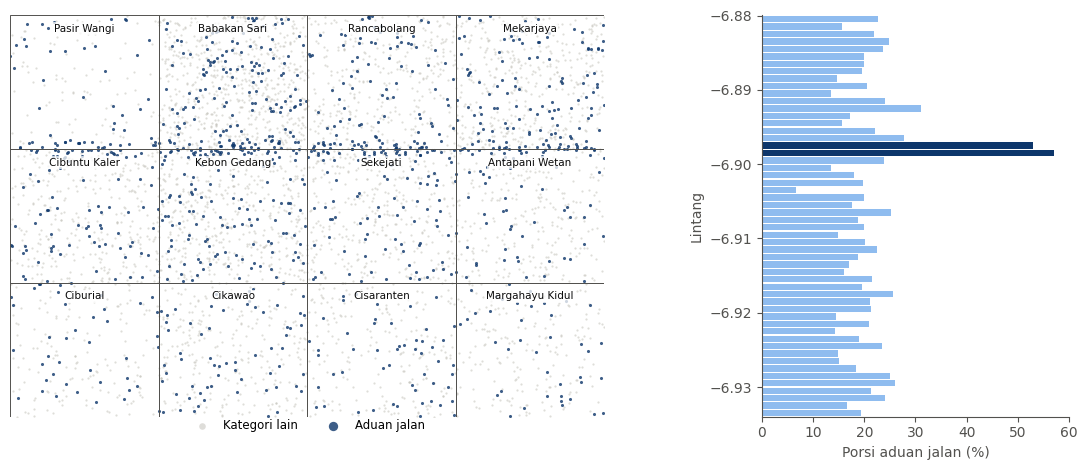

In [7]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [2.6, 1]})
lain = p[p.kategori != "jalan"]
jl = p[p.kategori == "jalan"]
ax.scatter(lain.x, lain.y, s=2.5, color=ABU, alpha=.55, linewidths=0, zorder=1, label="Kategori lain")
ax.scatter(jl.x, jl.y, s=5, color="#0d366b", alpha=.8, linewidths=0, zorder=2, label="Aduan jalan")
gambar_batas(ax)
for n in w.index:
    ax.text(w.lon_pusat[n], w.lat_pusat[n] + .0068, n, ha="center", fontsize=7.5, color=TEKS,
            bbox=dict(facecolor="white", alpha=.75, edgecolor="none", pad=1), zorder=4)
ax.legend(loc="upper center", bbox_to_anchor=(.5, .02), ncol=2, frameon=False, markerscale=3, fontsize=8.5)

ax2.barh(prof.lat_bawah + .0005, prof.pct_jalan, height=.00085,
         color=["#0d366b" if i in (-1, 0) else "#8fbcef" for i in prof.index])
ax2.set_ylim(-6.934, -6.88)
ax2.set_xlabel("Porsi aduan jalan (%)", color=TEKS2)
ax2.set_ylabel("Lintang", color=TEKS2)
ax2.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "gambar2_titik_jalan.png", bbox_inches="tight")
plt.show()